### ASTR 3300: Astrostatistics
***N. Pol***
___

# Homework 5
### Due: Tuesday, Oct. 27, 11:59 pm CST
---

## Only one problem this week

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw5_data_1.npy`. This is a (100 x 3) numpy array, containing some time-series measurements. It could be flux measurements from a star or some other transient. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC codes that we looked at in class (`emcee`, `pymc3`, `PTMCMCSampler`) perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$.

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

The priors for this model are the same as above for the equivalent parameters, and with $\ln\sigma_W\in\mathrm{Uniform}[-2,2]$. Following the examples from `Lecture 12` and from relevant web tutorials/documentation, use one of the nested sampling packages (`dynesty` or `UltraNest`) to compute the Bayesian evidence for this Gaussian model, and for the original burst model. Compute the Bayes factor, and state which model is the favored description of the data. *Hint: Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors. An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did above.*

### Solution

In [1]:
#part 1
import numpy as np
import matplotlib.pyplot as plt
#import file
data = np.load('hw_data/hw5_data_1.npy')
#name columns
time = data[:,0]
flux = data[:,1]
uncert = data[:,2]

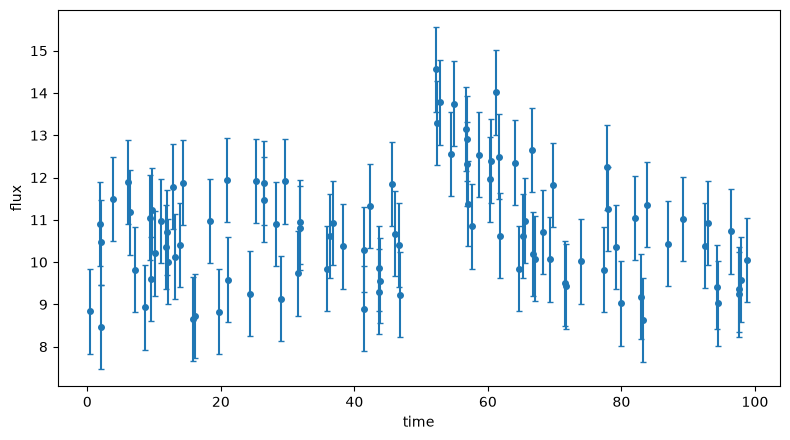

In [2]:
#plot
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(time, flux, yerr=uncert, fmt='o', ms=4, capsize=2)
ax.set_xlabel('time')
ax.set_ylabel('flux')
plt.tight_layout()
plt.show()

In [3]:
#part 2
#burst model function
def burst_model(theta, time):
    b, A, t_0, alpha = theta
    time = np.asarray(time)
    dt = np.clip(time - t_0, 0, None)
    return b + np.where(time >= t_0, A * np.exp(-alpha * dt), 0)

In [4]:
#likelihood function
def loglikelihood(x, time, flux, uncert):
    return np.sum(-(flux - burst_model(x, time))**2 / 2 / uncert**2)

def likelihood(x, time, flux, uncert):
    return np.exp(loglikelihood(x, time, flux, uncert))

In [5]:
#part 3
import emcee
#prior function
def prior(x):
    b, A, t_0, ln_alpha = x
    if 0 <= b <= 50 and 0 <= A <= 50 and 0 <= t_0 <= 100 and -5 <= ln_alpha <= 5:
        return 1.0 / (50 * 50 * 100 * 10)   
    return 0.0

def logprior(x):
    b, A, t_0, ln_alpha = x
    if 0 <= b <= 50 and 0 <= A <= 50 and 0 <= t_0 <= 100 and -5 <= ln_alpha <= 5:
        return 0.0                           
    return -np.inf

In [6]:
#posterior function
def posterior(x, time, flux, uncert):
    return likelihood(x, time, flux, uncert) * prior(x)

def logposterior(x, time, flux, uncert):
    lp = logprior(x)
    if not np.isfinite(lp):
        return -np.inf
    return lp + loglikelihood(x, time, flux, uncert)

In [7]:
#number of parameters
ndim = 4      
#other values needed
nwalkers = 50   
burn = 2000       
nsteps = 10000  

In [8]:
#following steps from lecture 11
np.random.seed(0)
starting_guesses = np.random.random((nwalkers, ndim))
starting_guesses = starting_guesses * np.array([50, 50, 100, 10]) + np.array([0, 0, 0, -5])

sampler = emcee.EnsembleSampler(nwalkers, ndim, logposterior, args=[time, flux, uncert])
sampler.run_mcmc(starting_guesses, nsteps)

emcee_trace = sampler.chain[:, burn:, :].reshape(-1, ndim)

C:\Users\sydne\AppData\Local\Temp\ipykernel_6488\1588684211.py:3: RuntimeWarning: overflow encountered in square
  return np.sum(-(flux - burst_model(x, time))**2 / 2 / uncert**2)
C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\emcee\moves\red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]


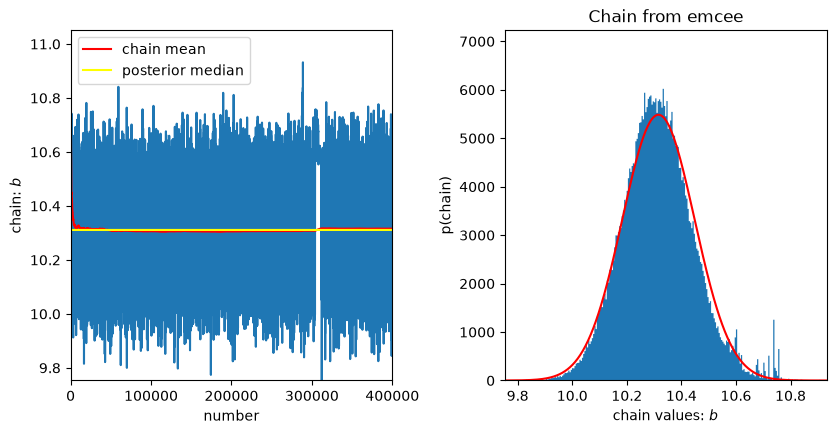

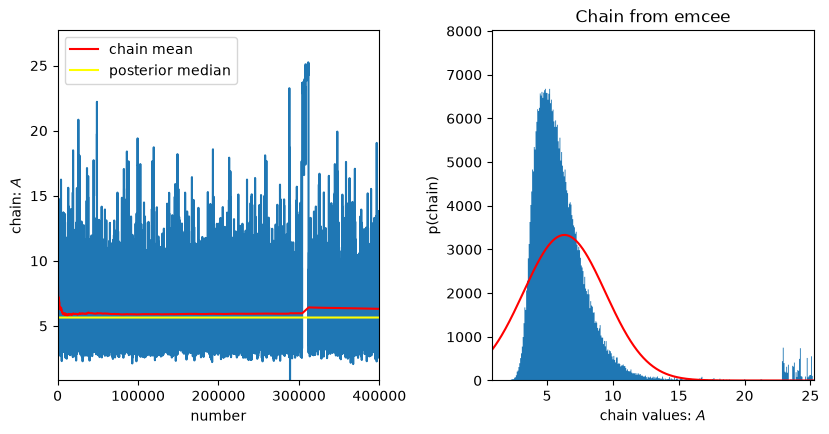

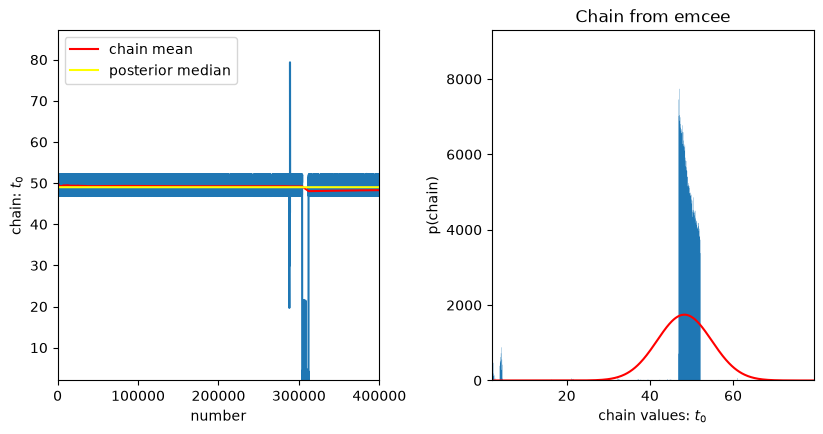

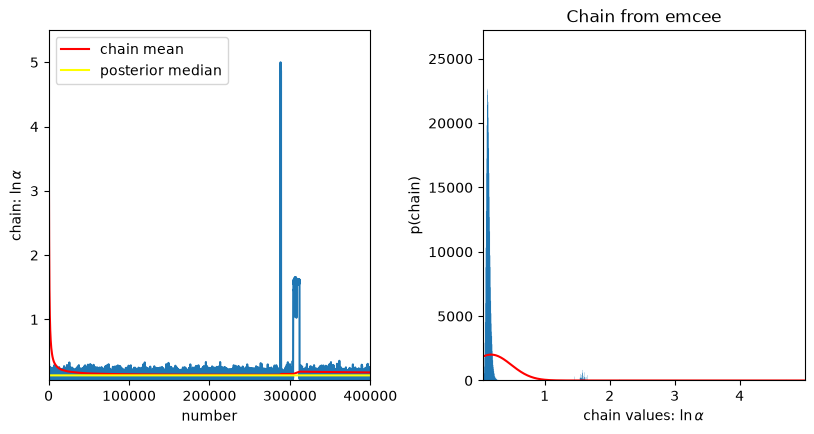

In [9]:
from scipy import stats

#names for parameters
param_names = [r'$b$', r'$A$', r'$t_0$', r'$\ln\alpha$']

#plot code from lecture 11 run over all parameters
for i in range(ndim):
    fig = plt.figure(figsize=(9, 5))
    fig.subplots_adjust(left=0.11, right=0.95,
                        wspace=0.35, bottom=0.18)

    chainE = emcee_trace[:, i]          
    M = np.size(chainE)

    ax1 = fig.add_subplot(121)
    xgrid = np.linspace(1, M, M)
    ax1.plot(xgrid, chainE)
    ax1.axis([0, M, np.min(chainE), np.max(chainE) + 0.1 * np.ptp(chainE)])
    ax1.set_xlabel('number')
    ax1.set_ylabel('chain: ' + param_names[i])

    meanC = np.cumsum(chainE) / xgrid
    ax1.plot(xgrid, meanC, c='red', label='chain mean')
    ax1.plot(xgrid, 0 * xgrid + np.median(chainE),
             c='yellow', label='posterior median')
    ax1.legend()

    ax2 = fig.add_subplot(122)
    Nchain = np.size(chainE)
    Nhist, bins, patches = ax2.hist(chainE, bins='auto', histtype='stepfilled')

    binwidth = bins[1] - bins[0]
    mu, sig = np.mean(chainE), np.std(chainE)
    valGrid = np.linspace(bins[0], bins[-1], 500)
    gauss = Nchain * binwidth * stats.norm(mu, sig).pdf(valGrid)
    ax2.plot(valGrid, gauss, c='red')

    ax2.set_ylabel('p(chain)')
    ax2.set_xlabel('chain values: ' + param_names[i])
    ax2.set_xlim(bins[0], bins[-1])
    ax2.set_ylim(0, 1.2 * max(np.max(gauss), np.max(Nhist)))
    ax2.set_title(r'Chain from emcee')

    plt.show()

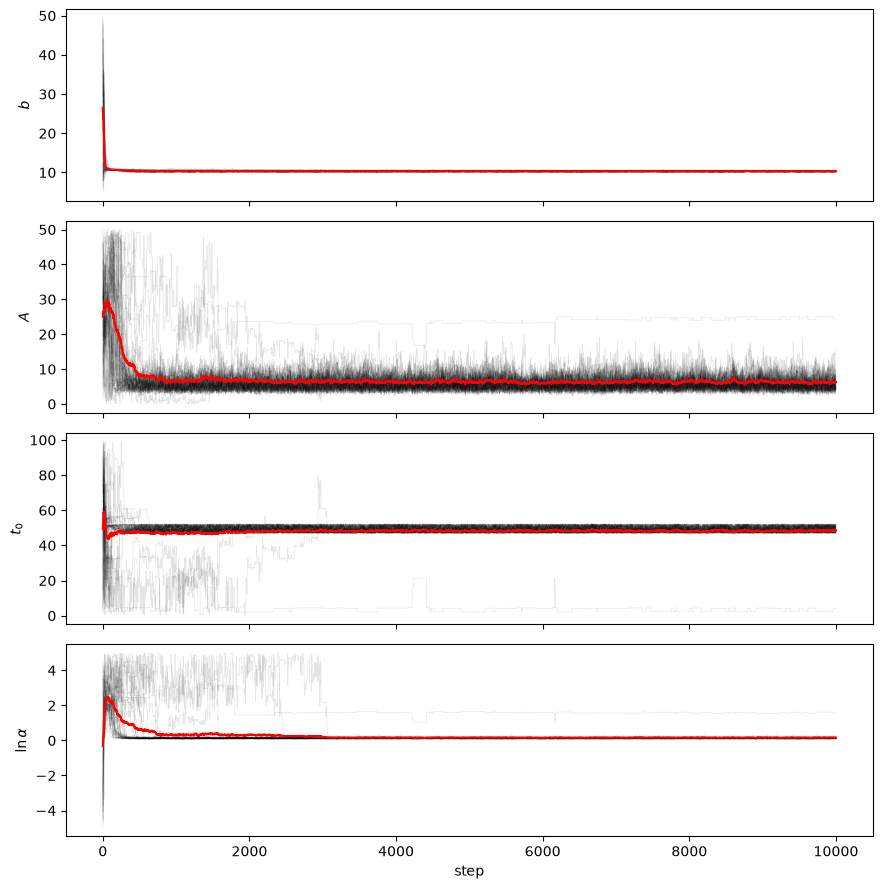

In [10]:
#part 4
full_chain = sampler.chain   

#plot
fig, axes = plt.subplots(ndim, 1, figsize=(9, 9), sharex=True)
steps = np.arange(full_chain.shape[1])

#loop over all parameters
for i in range(ndim):
    axes[i].plot(steps, full_chain[:, :, i].T, 'k', alpha=0.1, lw=0.5)   
    axes[i].plot(steps, full_chain[:, :, i].mean(axis=0), 'r', lw=1.5)   
    axes[i].set_ylabel(param_names[i])
axes[-1].set_xlabel('step')
plt.tight_layout()
plt.show()

In [32]:
#auto-correlation
good_chain = full_chain[good]                        # (49, nsteps, ndim)

tau = emcee.autocorr.integrated_time(good_chain[:, burn:, :].transpose(1, 0, 2), tol=0)
print("Autocorrelation times:", tau)

thin = int(np.ceil(tau.max()))
emcee_trace_thin = good_chain[:, burn::thin, :].reshape(-1, ndim)
print("Thinning factor:", thin, " Samples:", emcee_trace_thin.shape[0])

Autocorrelation times: [61.15370774 81.25404375 80.41831973 77.15368349]
Thinning factor: 82  Samples: 4802


In [34]:
#set thinning factor
thin = int(np.ceil(tau.max()))
emcee_trace_thin = good_chain[:, burn::thin, :].reshape(-1, ndim)

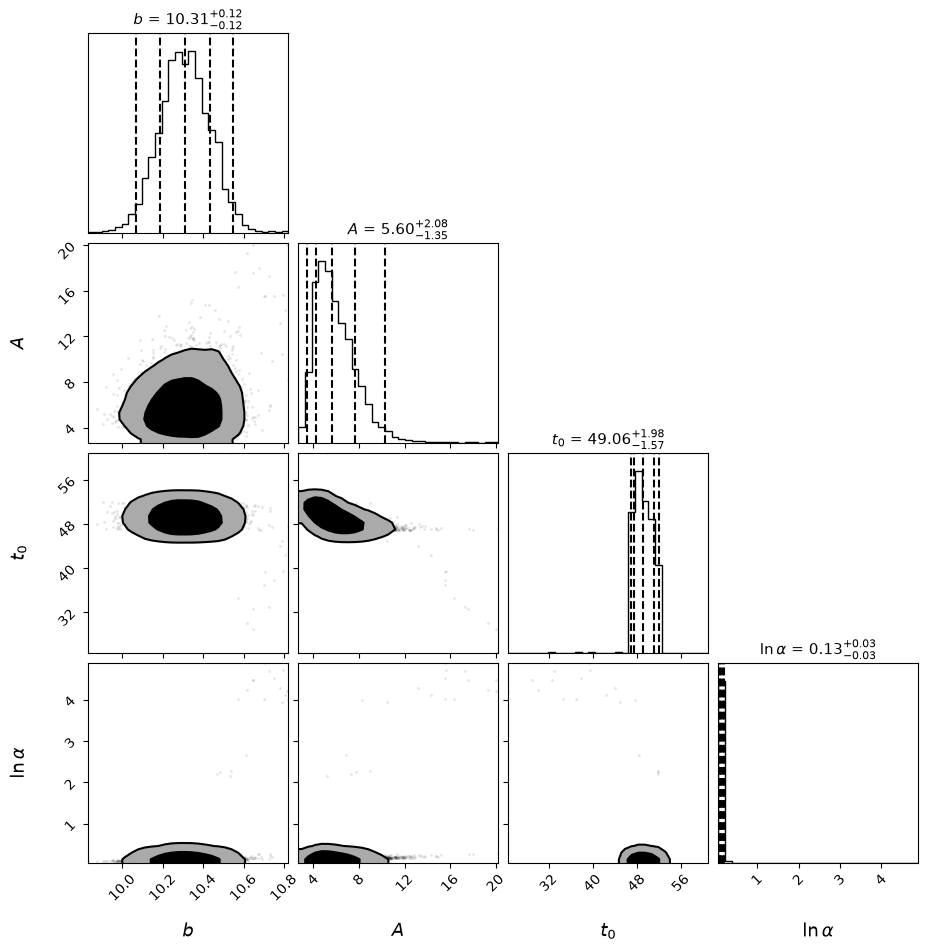

In [35]:
#part 5
import corner

#plot
fig = corner.corner(
    emcee_trace_thin,
    labels=param_names,
    levels=(0.68, 0.95),                    
    quantiles=[0.025, 0.16, 0.5, 0.84, 0.975], 
    show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84],     
    title_fmt=".2f",
    title_kwargs={"fontsize": 11},
    label_kwargs={"fontsize": 13},
    bins=30,
    smooth=1.0,
    plot_datapoints=True,
    plot_density=False,
    fill_contours=True,
)
plt.show()

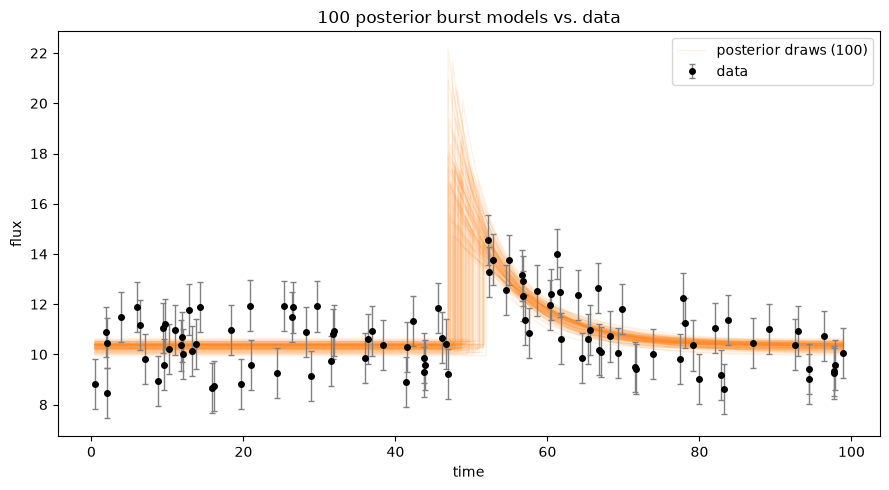

In [36]:
#part 6
#choosing 100 random samples
np.random.seed(1)
idx = np.random.choice(len(emcee_trace_thin), size=100, replace=False)
draws = emcee_trace_thin[idx]

#time grid
time_grid = np.linspace(time.min(), time.max(), 2000)

#plot
fig, ax = plt.subplots(figsize=(9, 5))

#loop over each draw
for k, x in enumerate(draws):
    tg = np.sort(np.append(time_grid, [x[2] - 1e-9, x[2]]))
    ax.plot(tg, burst_model(x, tg), color='C1', alpha=0.1, lw=1,
            label='posterior draws (100)' if k == 0 else None)
    
#error
ax.errorbar(time, flux, yerr=uncert, fmt='o', ms=4, color='k',
            ecolor='gray', elinewidth=1, capsize=2, label='data', zorder=3)

ax.set_xlabel('time')
ax.set_ylabel('flux')
ax.set_title('100 posterior burst models vs. data')
ax.legend()
plt.tight_layout()
plt.show()

In [37]:
%pip install dynesty

Note: you may need to restart the kernel to use updated packages.


In [38]:
#part 7
#following lecture 12
import dynesty
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc

#other possible model
def gauss_model(x, time):
    b, A, t_0, ln_sigma_W = x
    return b + A * np.exp(-(time - t_0)**2 / 2 / np.exp(ln_sigma_W)**2)

In [39]:
#log likelihood functions (from lecture 12)
lnorm = -0.5 * np.sum(np.log(2 * np.pi * uncert**2))

def loglike_burst(x):
    return -0.5 * np.sum((flux - burst_model(x, time))**2 / uncert**2) + lnorm

def loglike_gauss(x):
    return -0.5 * np.sum((flux - gauss_model(x, time))**2 / uncert**2) + lnorm

In [40]:
#sample transformation functions (from lecture 12)
def ptform_burst(u):
    return np.array([50. * u[0], 50. * u[1], 100. * u[2], 10. * u[3] - 5.])

def ptform_gauss(u):
    return np.array([50. * u[0], 50. * u[1], 100. * u[2], 4. * u[3] - 2.])

In [41]:
#static nested sampling for both models
sampler_burst = dynesty.NestedSampler(loglike_burst, ptform_burst, ndim,
                                      nlive=500, rstate=np.random.default_rng(0))
sampler_burst.run_nested()
res_burst = sampler_burst.results

sampler_gauss = dynesty.NestedSampler(loglike_gauss, ptform_gauss, ndim,
                                      nlive=500, rstate=np.random.default_rng(1))
sampler_gauss.run_nested()
res_gauss = sampler_gauss.results

C:\Users\sydne\AppData\Local\Temp\ipykernel_6488\1187523035.py:5: RuntimeWarning: overflow encountered in square
  return -0.5 * np.sum((flux - burst_model(x, time))**2 / uncert**2) + lnorm
iter: 856 | bound: 0 | nc: 3 | ncall: 2771 | eff(%): 30.891 | loglstar: -4869.615 | logz: -4878.234 | dlogz: 4724.905 >  0.509                                                                        C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
iter: 2271 | bound: 5 | nc: 12 | ncall: 20577 | eff(%): 11.037 | loglstar: -234.927 | logz: -243.731 | dlogz: 75.239 >  0.509                                                                         C:\Users\sydne\AppData\Local\Temp\ipykernel_6488\1187523035.py:5: RuntimeWarning: overflow encountered in square
  return -0.5 * np.sum((flux - burst_model(x, time))**2 / uncert**2) + lnorm
iter: 2273 | bound: 5 | nc: 4

In [42]:
#evidences and Bayes factor
lnZ_burst = res_burst.logz[-1]
lnZ_gauss = res_gauss.logz[-1]

lnB = lnZ_burst - lnZ_gauss                 
print(lnB)

1.9102246948142465


positive lnB, so burst model is favored

In [43]:
#equal weight posterior samples
def equal_samples(res):
    weights = np.exp(res.logwt - res.logz[-1])
    return dyfunc.resample_equal(res.samples, weights)

samples_burst_ns = equal_samples(res_burst)

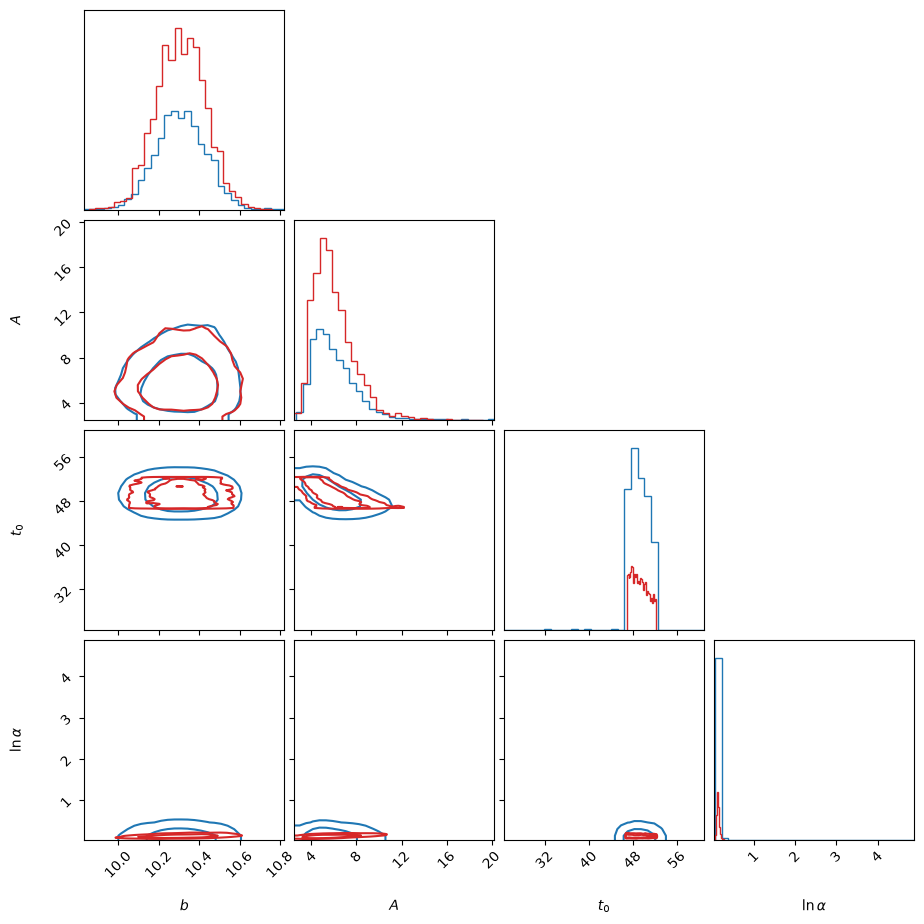

In [44]:
#checking to see if i get an equivalent corner plot to the one above
fig = corner.corner(emcee_trace_thin, labels=param_names, color='C0', levels=(0.68, 0.95), bins=30, smooth=1.0,
          plot_datapoints=False, plot_density=False)
corner.corner(samples_burst_ns, labels=param_names, color='C3', fig=fig, levels=(0.68, 0.95), bins=30, smooth=1.0,
          plot_datapoints=False, plot_density=False)
plt.show()  

seem to line up well